# Heart Disease Prediction System

> ### 🌐 Live Deployment Link: https://heart-disease-predictor-v2cadzsyxzp6anvqzmk4mm.streamlit.app

## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Check Python is installed
```
python --version
```
Any Python 3.9 - 3.13 should work.

### 2. Create a virtual environment
**Windows:** `python -m venv venv`  |  **macOS / Linux:** `python3 -m venv venv`

### 3. Activate the virtual environment
**Windows (Command Prompt):** `venv\Scripts\activate.bat`
**Windows (PowerShell):** `venv\Scripts\Activate.ps1`
*(If PowerShell blocks this, run once: `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`)*
**macOS / Linux:** `source venv/bin/activate`

### 4. Install the required packages
```
pip install -r requirements.txt
```

### 5. Register the environment as a Jupyter kernel (recommended)
```
python -m ipykernel install --user --name=heart-venv --display-name "Python (heart-venv)"
```
Then choose **Kernel -> Change Kernel -> Python (heart-venv)**.

### 6. Launch Jupyter and run everything
```
jupyter notebook
```
Open this file and click **Kernel -> Restart & Run All**.

### 7. Files that must be in the same folder as this notebook
- `processed.cleveland.data` (the original UCI file; if it is missing, Step 2 tries to download it)

---

## Introduction

##### **Definition**
A binary classification ML task that predicts whether a patient has heart disease (**Yes**) or not (**No**) from four medical attributes.

##### **Application**
It is used for learning the complete machine learning cycle on structured data, and as a simple example of how ML can support medical screening. **It is only a classroom demo and must never be used to diagnose a real patient.**

##### **Data Source**
UCI Machine Learning Repository - *Heart Disease* dataset, **Cleveland** database (303 patients, 14 attributes).
Link: https://archive.ics.uci.edu/dataset/45/heart+disease
Credit (as requested by the data donors): Robert Detrano, M.D., Ph.D. (V.A. Medical Center, Long Beach and Cleveland Clinic Foundation).

##### **Assignment Constraint**
Only **4 input attributes** are used (selected in Step 4).

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Original UCI Name** | **Possible Values** |
| --- | --- | --- |
| **ChestPain** | cp | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **ExerciseAngina** | exang | No, Yes |
| **MajorVessels** | ca | Zero, One, Two, Three |
| **Thalassemia** | thal | Normal, Fixed Defect, Reversible Defect |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | Yes, No |

### Examples (Heart Disease Dataset - first 5 patients)

| ChestPain | ExerciseAngina | MajorVessels | Thalassemia | HeartDisease |
| :--- | :---: | :---: | :--- | :---: |
| Typical Angina | No | Zero | Fixed Defect | No |
| Asymptomatic | Yes | Three | Normal | Yes |
| Asymptomatic | Yes | Two | Reversible Defect | Yes |
| Non-anginal Pain | No | Zero | Normal | No |
| Atypical Angina | No | Zero | Normal | No |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | Khadija Tul Kubra |
| **Registration No.** | FA24-BSE-055 |
| **Course** | AIC354 - Machine Learning Fundamentals (Fall 2026) |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Program Name** | heart_disease_project |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3 (exact version is printed in Step 1) |
| **Libraries** | NumPy, Pandas, Pickle (built-in), scikit-learn, PrettyTable, Matplotlib, Seaborn |
| **Deployment** | Streamlit Community Cloud (fallbacks: PythonAnywhere, Hugging Face Spaces) |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data (Data Collection)
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
  - Step 3.3: Visualize the Candidate Attributes
- Step 4: Feature Extraction (Select the 4 Input Attributes)
  - Step 4.1: Rank the Attributes
  - Step 4.2: Select Exactly 4 Attributes
  - Step 4.3: Build the Final Sample Data
  - Step 4.4: Visualize the Selected Attributes
- Step 5: Label Encoding the Sample Data (Input and Output are converted into Numeric Representation)
  - Step 5.1: Train the Label Encoders
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
  - Step 6.5: Compare SVC vs. Logistic Regression vs. Decision Tree
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs / Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
  - Step 7.6: Cross-Validation (a more reliable accuracy estimate)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- Step 10: Deploy Your Model on the Cloud
  - Step 10.1: Why Deploy a Model?
  - Step 10.2: Create the Deployment Folder
  - Step 10.3: Write the Web App Code
  - Step 10.4: Test the Deployment Folder Locally
  - Step 10.5: Upload to GitHub and Deploy on Streamlit Community Cloud
  - Step 10.6: Fallback Options (PythonAnywhere, Hugging Face Spaces)
  - Step 10.7: Troubleshooting
  - Step 10.8: Put Your Live Link at the Top of This Notebook
- Conclusion

## Code – Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This cell imports every library used in the notebook: tools for data handling,
label encoding, splitting data, training models, measuring accuracy and
drawing charts. It also prints the version of each tool, so you can see
exactly which environment produced the results.
"""

import os
import sys
import shutil
import urllib.request

# Numerical computing (arrays, math)
import numpy as np

# Data handling (DataFrames, reading/writing CSV files)
import pandas as pd

# Pickle (saving and loading the trained model)
import pickle

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Clean tables and formatted text output
from prettytable import PrettyTable
from IPython.display import display, Markdown

# scikit-learn tools
import sklearn
from sklearn import svm
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib  :", plt.matplotlib.__version__)
print("Seaborn     :", sns.__version__)

Python      : 3.11.5
NumPy       : 2.2.6
Pandas      : 2.3.3
scikit-learn: 1.7.2
Matplotlib  : 3.10.9
Seaborn     : 0.13.2


### Step 2: Load Sample Data (Data Collection)

The data comes from the UCI repository. The file `processed.cleveland.data` has **303 patients** and **14 columns** but **no header row**, so we must give the column names ourselves.

| Column | Meaning | Values |
| --- | --- | --- |
| age | Age in years | number |
| sex | Sex | 1 = male, 0 = female |
| cp | Chest pain type | 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| trestbps | Resting blood pressure (mm Hg) | number |
| chol | Serum cholesterol (mg/dl) | number |
| fbs | Fasting blood sugar > 120 mg/dl | 1 = true, 0 = false |
| restecg | Resting ECG result | 0 = normal, 1 = ST-T wave abnormality, 2 = left ventricular hypertrophy |
| thalach | Maximum heart rate achieved | number |
| exang | Exercise-induced angina | 1 = yes, 0 = no |
| oldpeak | ST depression induced by exercise | number |
| slope | Slope of peak exercise ST segment | 1 = upsloping, 2 = flat, 3 = downsloping |
| ca | Major vessels (0-3) coloured by fluoroscopy | 0, 1, 2, 3 |
| thal | Thallium stress test result | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| num | **Diagnosis of heart disease (the output)** | 0 = no disease, 1-4 = disease present |

A missing value is written as `?` in this file.

In [2]:
"""
Purpose of this section:
-------------------------
Loads the UCI Cleveland heart disease data into a pandas DataFrame.

FALLBACK: if the data file is not in the notebook folder, the code tries to
download it from the UCI website. If that also fails (for example, no
internet), it stops with a clear message telling you what to do.
"""

RAW_FILE = "processed.cleveland.data"
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

if not os.path.exists(RAW_FILE):
    print(RAW_FILE, "not found in this folder - trying to download it from UCI ...")
    try:
        urllib.request.urlretrieve(UCI_URL, RAW_FILE)
        print("Downloaded:", RAW_FILE)
    except Exception as download_error:
        raise FileNotFoundError(
            "Could not find or download '" + RAW_FILE + "'. Please download the dataset from "
            "https://archive.ics.uci.edu/dataset/45/heart+disease , unzip it, and copy "
            "'processed.cleveland.data' into the same folder as this notebook."
        ) from download_error

# The file has no header row, so we provide the 14 column names ourselves.
# na_values="?" tells pandas that "?" means "missing value".
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
raw_data = pd.read_csv(RAW_FILE, header=None, names=column_names, na_values="?")

print("\n\nSample Data (first 10 of", len(raw_data), "patients):")
print("=========================================\n")
display(raw_data.head(10))



Sample Data (first 10 of 303 patients):



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
Helps us understand the dataset:
1. Attribute (column) names
2. Number of instances (rows)
3. Data types and basic statistics
4. Missing values
5. How many patients have / do not have heart disease
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(raw_data.columns))

print("\n\nNumber of Instances in Sample Data:", len(raw_data))
print("========================================\n")

print("\nBasic statistics of the numeric attributes:")
display(raw_data.describe().round(2))

print("\nMissing values in each attribute:")
print("=================================\n")
missing_counts = raw_data.isna().sum()
print(missing_counts[missing_counts > 0].to_string())
print("\nTotal rows that contain at least one missing value:", int(raw_data.isna().any(axis=1).sum()))

print("\n\nValues of the output attribute 'num' (0 = no disease, 1-4 = disease present):")
print("============================================================================\n")
print(raw_data["num"].value_counts().sort_index().to_string())



Attributes in Sample Data:

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


Number of Instances in Sample Data: 303


Basic statistics of the numeric attributes:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00



Missing values in each attribute:

ca      4
thal    2

Total rows that contain at least one missing value: 6


Values of the output attribute 'num' (0 = no disease, 1-4 = disease present):

num
0    164
1     55
2     36
3     35
4     13


#### Step 3.2: Pre-process Sample Data

The raw data needs three pre-processing actions:

1. **Missing values** - only `ca` (4 patients) and `thal` (2 patients) have `?` values. That is 6 of 303 rows (about 2%). The simplest safe choice is to **remove those 6 rows**; we lose almost nothing.
2. **Binary output** - the original output `num` has 5 levels (0 to 4). The UCI documentation says experiments only try to separate *absence* (0) from *presence* (1, 2, 3, 4), so we convert it to **No / Yes**.
3. **Whole numbers** - after removing missing values, `ca` and `thal` can be stored as integers.

In [4]:
"""
Purpose of this section:
-------------------------
Cleans the raw data:
1. Removes the rows that contain missing values.
2. Converts the output 'num' (0-4) into a Yes/No heart disease label.
3. Stores the code columns as whole numbers.
"""

rows_before = len(raw_data)

# 1. Remove rows with missing values and renumber the rows
clean_data = raw_data.dropna().reset_index(drop=True)
print("Rows before cleaning :", rows_before)
print("Rows after cleaning  :", len(clean_data))
print("Rows removed         :", rows_before - len(clean_data))

# 2. Binary output: 0 -> "No", 1/2/3/4 -> "Yes"
clean_data["HeartDisease"] = clean_data["num"].apply(lambda value: "Yes" if value > 0 else "No")
clean_data["DiseaseFlag"] = (clean_data["num"] > 0).astype(int)   # 1/0 version, used only for charts and ranking

# 3. Whole-number columns
for column in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    clean_data[column] = clean_data[column].astype(int)

print("\nMissing values left:", int(clean_data.isna().sum().sum()))
print("\nHeart disease count after cleaning:")
print(clean_data["HeartDisease"].value_counts().to_string())

Rows before cleaning : 303
Rows after cleaning  : 297
Rows removed         : 6

Missing values left: 0

Heart disease count after cleaning:
HeartDisease
No     160
Yes    137


#### Step 3.3: Visualize the Candidate Attributes

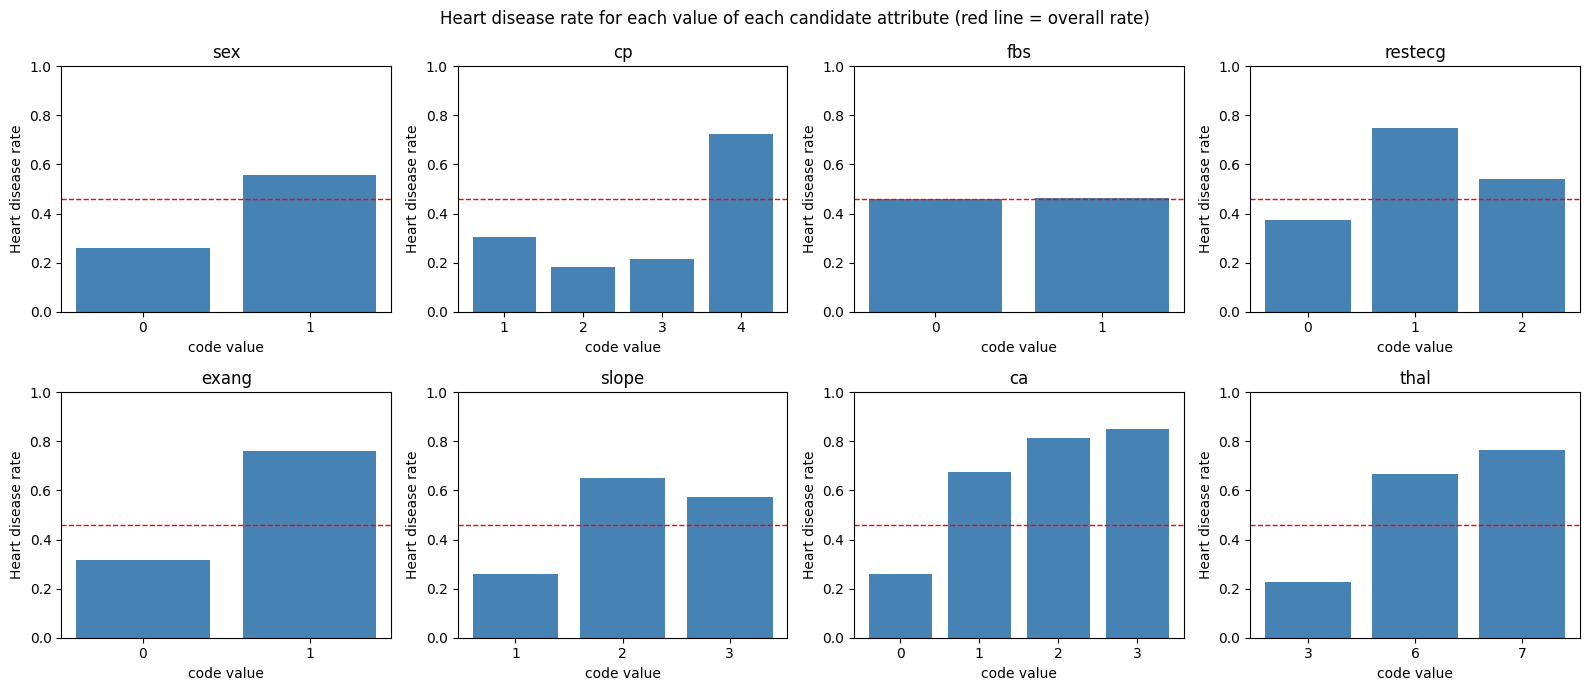

Observation: ca, thal, exang and cp change the disease rate the most;
fbs (fasting blood sugar) stays close to the overall rate, so it tells us very little.


In [5]:
"""
Purpose of this section:
-------------------------
Before choosing which attributes to use, we SEE how the chance of heart disease
changes with each categorical attribute. A bar far above or below the
overall average means that attribute value tells us a lot about the output.
"""

candidate_attributes = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
overall_rate = clean_data["DiseaseFlag"].mean()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for axis, attribute in zip(axes.flat, candidate_attributes):
    rate = clean_data.groupby(attribute)["DiseaseFlag"].mean()
    axis.bar(rate.index.astype(str), rate.values, color="steelblue")
    axis.axhline(overall_rate, color="red", linestyle="--", linewidth=1)
    axis.set_title(attribute)
    axis.set_xlabel("code value")
    axis.set_ylabel("Heart disease rate")
    axis.set_ylim(0, 1)

plt.suptitle("Heart disease rate for each value of each candidate attribute (red line = overall rate)")
plt.tight_layout()
plt.show()

print("Observation: ca, thal, exang and cp change the disease rate the most;")
print("fbs (fasting blood sugar) stays close to the overall rate, so it tells us very little.")

### Step 4: Feature Extraction (Select the 4 Input Attributes)

The assignment says: **select only 4 input attributes**. We do not guess - we let the data decide.

We only look at the **categorical** attributes, because this notebook (like the Titanic notebook) uses *Label Encoding* to turn categories into numbers. We rank them with two standard scores:

- **Chi-square score** - how strongly the attribute and the output depend on each other (higher = stronger).
- **Mutual information** - how much knowing the attribute reduces our uncertainty about the output (higher = stronger).

#### Step 4.1: Rank the Attributes

In [6]:
"""
Purpose of this section:
-------------------------
Ranks the 8 categorical attributes with the Chi-square score and with
Mutual Information.
"""

ranking_inputs = clean_data[candidate_attributes]
ranking_output = clean_data["DiseaseFlag"]

chi2_scores, chi2_p_values = chi2(ranking_inputs, ranking_output)
mutual_info_scores = mutual_info_classif(ranking_inputs, ranking_output, discrete_features=True, random_state=0)

attribute_ranking = pd.DataFrame({
    "Chi2 score": chi2_scores.round(2),
    "Chi2 p-value": chi2_p_values,
    "Mutual information": mutual_info_scores.round(3),
}, index=candidate_attributes).sort_values("Chi2 score", ascending=False)

print("Attribute ranking (best first):")
print("===============================\n")
display(attribute_ranking.style.format({"Chi2 p-value": "{:.2e}"}))

top4_by_chi2 = set(attribute_ranking.sort_values("Chi2 score", ascending=False).head(4).index)
top4_by_mi = set(attribute_ranking.sort_values("Mutual information", ascending=False).head(4).index)
print("Top 4 by Chi-square        :", sorted(top4_by_chi2))
print("Top 4 by Mutual information:", sorted(top4_by_mi))

Attribute ranking (best first):



,Chi2 score,Chi2 p-value,Mutual information
ca,82.730000,9.40e-20,0.128000
thal,65.220000,6.69e-16,0.146000
exang,35.510000,2.54e-09,0.092000
cp,14.590000,1.34e-04,0.137000
restecg,8.130000,4.34e-03,0.016000
slope,7.830000,5.14e-03,0.075000
sex,7.440000,6.36e-03,0.040000
fbs,0.000000,9.60e-01,0.000000


Top 4 by Chi-square        : ['ca', 'cp', 'exang', 'thal']
Top 4 by Mutual information: ['ca', 'cp', 'exang', 'thal']


#### Step 4.2: Select Exactly 4 Attributes

Both scores agree on the same four attributes: **`cp`, `exang`, `ca` and `thal`**. They also make medical sense: the type of chest pain, pain during exercise, how many major vessels show blockage, and the stress-test result.

In [7]:
"""
Purpose of this section:
-------------------------
Fixes the 4 selected input attributes and checks the assignment constraint.
"""

selected_attributes = ["cp", "exang", "ca", "thal"]

print("Selected input attributes:", selected_attributes)
print("Same as top 4 by Chi-square?        ", set(selected_attributes) == top4_by_chi2)
print("Same as top 4 by Mutual information?", set(selected_attributes) == top4_by_mi)

assert len(selected_attributes) == 4, "The assignment allows exactly 4 input attributes."
print("\nConstraint satisfied: exactly 4 input attributes are used.")

Selected input attributes: ['cp', 'exang', 'ca', 'thal']
Same as top 4 by Chi-square?         True
Same as top 4 by Mutual information? True

Constraint satisfied: exactly 4 input attributes are used.


#### Step 4.3: Build the Final Sample Data

Now we keep only the 4 selected inputs plus the output, and replace the numeric codes with **readable words** (exactly like the Titanic data, where values were words such as *First* or *Male*). This is also the table that will be saved as `sample-data.csv`.

In [8]:
"""
Purpose of this section:
-------------------------
Builds the final Sample Data table:
- keeps only the 4 selected input attributes + the output
- replaces numeric codes with readable words, using the UCI documentation
- saves the result as sample-data.csv
"""

# Code -> word dictionaries (taken from the UCI attribute documentation)
chest_pain_words = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-anginal Pain", 4: "Asymptomatic"}
exercise_angina_words = {0: "No", 1: "Yes"}
major_vessels_words = {0: "Zero", 1: "One", 2: "Two", 3: "Three"}
thalassemia_words = {3: "Normal", 6: "Fixed Defect", 7: "Reversible Defect"}

sample_data = pd.DataFrame({
    "ChestPain": clean_data["cp"].map(chest_pain_words),
    "ExerciseAngina": clean_data["exang"].map(exercise_angina_words),
    "MajorVessels": clean_data["ca"].map(major_vessels_words),
    "Thalassemia": clean_data["thal"].map(thalassemia_words),
    "HeartDisease": clean_data["HeartDisease"],
})

# Safety check: every code must have been translated into a word
if sample_data.isna().any().any():
    raise ValueError("Some codes could not be translated. Check the dictionaries above.")

sample_data.to_csv("sample-data.csv", index=False, header=True)

print("Sample Data (first 10 rows):")
print("============================\n")
display(sample_data.head(10))
print("Saved: sample-data.csv  -", sample_data.shape[0], "rows x", sample_data.shape[1], "columns")

Sample Data (first 10 rows):



,ChestPain,ExerciseAngina,MajorVessels,Thalassemia,HeartDisease
0,Typical Angina,No,Zero,Fixed Defect,No
1,Asymptomatic,Yes,Three,Normal,Yes
2,Asymptomatic,Yes,Two,Reversible Defect,Yes
3,Non-anginal Pain,No,Zero,Normal,No
4,Atypical Angina,No,Zero,Normal,No
5,Atypical Angina,No,Zero,Normal,No
6,Asymptomatic,No,Two,Normal,Yes
7,Asymptomatic,Yes,Zero,Normal,No
8,Asymptomatic,No,One,Reversible Defect,Yes
9,Asymptomatic,Yes,Zero,Reversible Defect,Yes


Saved: sample-data.csv  - 297 rows x 5 columns


#### Step 4.4: Visualize the Selected Attributes

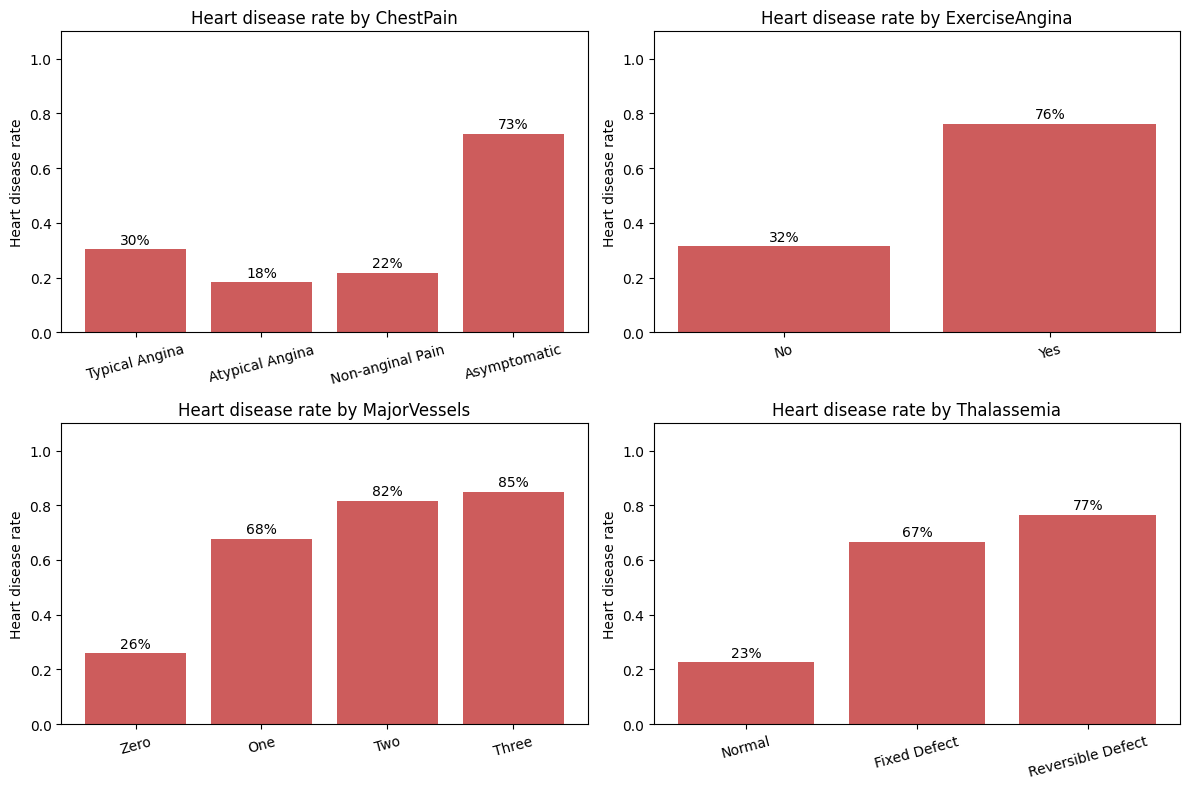

Columns kept in sample_data: ['ChestPain', 'ExerciseAngina', 'MajorVessels', 'Thalassemia', 'HeartDisease']


In [9]:
"""
Purpose of this section:
-------------------------
Shows the heart disease rate for every value of the 4 selected attributes,
this time with readable labels.
"""

sample_data["DiseaseFlag"] = (sample_data["HeartDisease"] == "Yes").astype(int)
attribute_orders = {
    "ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"],
    "ExerciseAngina": ["No", "Yes"],
    "MajorVessels": ["Zero", "One", "Two", "Three"],
    "Thalassemia": ["Normal", "Fixed Defect", "Reversible Defect"],
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, (attribute, order) in zip(axes.flat, attribute_orders.items()):
    rate = sample_data.groupby(attribute)["DiseaseFlag"].mean().reindex(order)
    bars = axis.bar(order, rate.values, color="indianred")
    axis.set_title("Heart disease rate by " + attribute)
    axis.set_ylabel("Heart disease rate")
    axis.set_ylim(0, 1.1)
    axis.tick_params(axis="x", rotation=15)
    for bar, value in zip(bars, rate.values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.0%}", ha="center")

plt.tight_layout()
plt.show()

# DiseaseFlag was only needed for the charts - remove it so it never reaches the model
sample_data = sample_data.drop(columns=["DiseaseFlag"])
print("Columns kept in sample_data:", list(sample_data.columns))

### Step 5: Label Encoding the Sample Data (Input and Output are converted into Numeric Representation)

Machine learning models work with **numbers**, not words. *Label Encoding* gives every category its own whole number. The `LabelEncoder` of scikit-learn numbers the categories in **alphabetical order**. Example for `ExerciseAngina`: No -> 0, Yes -> 1.

#### Step 5.1: Train the Label Encoders

In [10]:
"""
Purpose of this section:
-------------------------
Sets up and trains one Label Encoder for every attribute.

Steps:
1. Write down ALL possible values of each attribute (not only the values that
   happen to appear in the data). The web app uses exactly the same lists.
2. Create one LabelEncoder per attribute.
3. Train (fit) each LabelEncoder on its list of values.
"""

# All possible values of each attribute
valid_values = {
    "ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"],
    "ExerciseAngina": ["No", "Yes"],
    "MajorVessels": ["Zero", "One", "Two", "Three"],
    "Thalassemia": ["Normal", "Fixed Defect", "Reversible Defect"],
    "HeartDisease": ["Yes", "No"],
}

chestpain = pd.DataFrame({"ChestPain": valid_values["ChestPain"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": valid_values["ExerciseAngina"]})
majorvessels = pd.DataFrame({"MajorVessels": valid_values["MajorVessels"]})
thalassemia = pd.DataFrame({"Thalassemia": valid_values["Thalassemia"]})
heartdisease = pd.DataFrame({"HeartDisease": valid_values["HeartDisease"]})

# Create the LabelEncoder objects
chestpain_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
majorvessels_label_encoder = LabelEncoder()
thalassemia_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

# Train (fit) the encoders; np.ravel() flattens the column into a 1D array
chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
majorvessels_label_encoder.fit(np.ravel(majorvessels))
thalassemia_label_encoder.fit(np.ravel(thalassemia))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

# Show the numbers that every category received
all_label_encoders = {
    "ChestPain": chestpain_label_encoder,
    "ExerciseAngina": exerciseangina_label_encoder,
    "MajorVessels": majorvessels_label_encoder,
    "Thalassemia": thalassemia_label_encoder,
    "HeartDisease": heartdisease_label_encoder,
}
print("Numeric code given to every category:")
print("=====================================\n")
for attribute_name, encoder in all_label_encoders.items():
    codes = encoder.transform(encoder.classes_).tolist()
    print(attribute_name.ljust(15), dict(zip(encoder.classes_.tolist(), codes)))

Numeric code given to every category:

ChestPain       {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-anginal Pain': 2, 'Typical Angina': 3}
ExerciseAngina  {'No': 0, 'Yes': 1}
MajorVessels    {'One': 0, 'Three': 1, 'Two': 2, 'Zero': 3}
Thalassemia     {'Fixed Defect': 0, 'Normal': 1, 'Reversible Defect': 2}
HeartDisease    {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [11]:
"""
Purpose of this section:
-------------------------
Converts the output attribute 'HeartDisease' (No / Yes) into numbers (0 / 1).
"""

# Copy of the data where only the output is encoded
sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output["HeartDisease"] = heartdisease_label_encoder.transform(sample_data["HeartDisease"])

print("HeartDisease Attribute After Label Encoding (first 10 rows):")
print("============================================================\n")
before_after = pd.DataFrame({
    "HeartDisease": sample_data["HeartDisease"],
    "encoded_HeartDisease": sample_data_encoded_output["HeartDisease"],
})
display(before_after.head(10))

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("Saved: sample-data-encoded-output.csv")

HeartDisease Attribute After Label Encoding (first 10 rows):



,HeartDisease,encoded_HeartDisease
0,No,0
1,Yes,1
2,Yes,1
3,No,0
4,No,0
5,No,0
6,Yes,1
7,No,0
8,Yes,1
9,Yes,1


Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [12]:
"""
Purpose of this section:
-------------------------
Converts the 4 input attributes into numbers, so the model can use them.
"""

sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded["ChestPain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded["ExerciseAngina"] = exerciseangina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded["MajorVessels"] = majorvessels_label_encoder.transform(sample_data_encoded_output["MajorVessels"])
sample_data_encoded["Thalassemia"] = thalassemia_label_encoder.transform(sample_data_encoded_output["Thalassemia"])

# The output must stay in the LAST column (Step 6.2 relies on this)
assert list(sample_data_encoded.columns)[-1] == "HeartDisease"

print("Sample Data after Label Encoding (first 10 rows):")
print("=================================================\n")
display(sample_data_encoded.head(10))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)
print("Saved: sample-data-encoded.csv")

Sample Data after Label Encoding (first 10 rows):



,ChestPain,ExerciseAngina,MajorVessels,Thalassemia,HeartDisease
0,3,0,3,0,0
1,0,1,1,1,1
2,0,1,2,2,1
3,2,0,3,1,0
4,1,0,3,1,0
5,1,0,3,1,0
6,0,0,2,1,1
7,0,1,3,1,0
8,0,0,0,2,1
9,0,1,3,2,1


Saved: sample-data-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

- **Training data (80%)** teaches the model.
- **Testing data (20%)** checks the model on patients it has never seen.

We use `shuffle=True` with `stratify`, so both parts have the same share of heart-disease patients. `random_state=0` makes the split the same every time.

In [13]:
"""
Purpose of this section:
-------------------------
Splits the encoded data into Training Data (80%) and Testing Data (20%).
"""

training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"],
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape :", testing_data_encoded.shape)
print("\nHeart disease share in training data:", round(training_data_encoded["HeartDisease"].mean(), 3))
print("Heart disease share in testing data :", round(testing_data_encoded["HeartDisease"].mean(), 3))

Training Data shape: (237, 5)
Testing Data shape : (60, 5)

Heart disease share in training data: 0.46
Heart disease share in testing data : 0.467


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [14]:
"""
Purpose of this section:
-------------------------
Separates the inputs (features) and the output (label) of the training data.
"""

input_vector_train = training_data_encoded.iloc[:, :-1]    # all columns except the last
output_label_train = training_data_encoded.iloc[:, -1]     # the last column

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


#### Step 6.3: Train the Support Vector Classifier

In [15]:
"""
Purpose of this section:
-------------------------
Trains a Support Vector Classifier (SVC). An SVC finds the best boundary
between the two classes (heart disease / no heart disease).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [16]:
"""
Purpose of this section:
-------------------------
Saves the trained model to a file, so it can be reused (and deployed) without
training again.
"""

with open("svc_trained_model.pkl", "wb") as model_file:
    pickle.dump(svc_model, model_file)
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


#### Step 6.5: Compare SVC vs. Logistic Regression vs. Decision Tree

Different algorithms can give different results on the same data. We train two more models on the **same training data** and compare all three on the **same testing data**. The model that is saved and deployed stays the SVC (as in the Titanic notebook); this comparison only shows how it stands.


Model Comparison on Testing Data:
+---------------------+----------+-----------+--------+----------+
|        Model        | Accuracy | Precision | Recall | F1-score |
+---------------------+----------+-----------+--------+----------+
|   SVC (gamma=auto)  |   0.85   |    0.85   |  0.85  |   0.85   |
| Logistic Regression |   0.82   |    0.82   |  0.82  |   0.82   |
|    Decision Tree    |   0.8    |    0.8    |  0.8   |   0.8    |
+---------------------+----------+-----------+--------+----------+

Note: with 60 test patients, ONE patient changes accuracy by about 1.7 percentage points, so small differences are not meaningful.


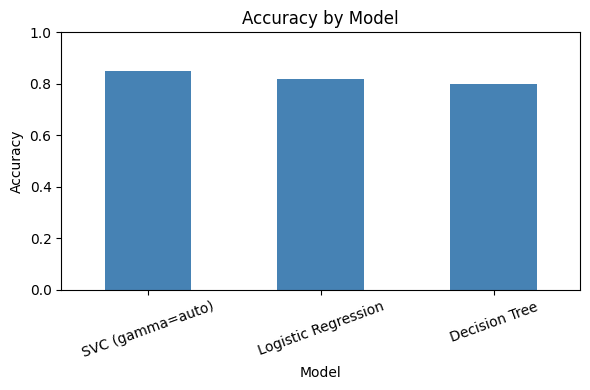

In [17]:
"""
Purpose of this section:
-------------------------
Trains Logistic Regression and a Decision Tree on the same training data and
compares them with the SVC on the testing data.
"""

compare_vectors_test = testing_data_encoded.iloc[:, :-1]
compare_labels_test = testing_data_encoded.iloc[:, -1]

candidate_models = {
    "SVC (gamma=auto)": svc_model,
    "Logistic Regression": LogisticRegression(random_state=0, max_iter=1000).fit(input_vector_train, np.ravel(output_label_train)),
    "Decision Tree": DecisionTreeClassifier(random_state=0).fit(input_vector_train, np.ravel(output_label_train)),
}

comparison_rows = []
for model_name, candidate in candidate_models.items():
    candidate_predictions = candidate.predict(compare_vectors_test)
    report = classification_report(compare_labels_test, candidate_predictions, output_dict=True, zero_division=0)["weighted avg"]
    comparison_rows.append({
        "Model": model_name,
        "Accuracy": round(accuracy_score(compare_labels_test, candidate_predictions), 2),
        "Precision": round(report["precision"], 2),
        "Recall": round(report["recall"], 2),
        "F1-score": round(report["f1-score"], 2),
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_table = PrettyTable()
comparison_table.field_names = list(comparison_df.columns)
for _, row in comparison_df.iterrows():
    comparison_table.add_row(list(row))

print("\nModel Comparison on Testing Data:")
print(comparison_table)
print("\nNote: with", len(compare_labels_test), "test patients, ONE patient changes accuracy by about",
      round(100 / len(compare_labels_test), 1), "percentage points, so small differences are not meaningful.")

comparison_df.set_index("Model")["Accuracy"].plot(kind="bar", figsize=(6, 4), title="Accuracy by Model", ylim=(0, 1), color="steelblue")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs / Labels of Testing Data

In [18]:
"""
Purpose of this section:
-------------------------
Separates the inputs (features) and the output (label) of the testing data.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


#### Step 7.2: Load the Saved Model

In [19]:
"""
Purpose of this section:
-------------------------
Loads the previously saved model from disk into memory.
"""

with open("svc_trained_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [20]:
"""
Purpose of this section:
-------------------------
Uses the loaded model to predict the output of every testing patient and
saves the predictions next to the real answers.
"""

model_predictions = testing_data_encoded.copy()
model_predictions["Predictions"] = model.predict(input_vector_test)
model_predictions.to_csv("model-predictions.csv", index=False, header=True)

print("\n\nPredictions Returned by svc_trained_model (first 15 rows):")
print("==========================================================\n")
display(model_predictions.head(15))
print("Saved: model-predictions.csv")



Predictions Returned by svc_trained_model (first 15 rows):



,ChestPain,ExerciseAngina,MajorVessels,Thalassemia,HeartDisease,Predictions
69,2,0,3,1,1,0
2,0,1,2,2,1,1
94,0,1,0,2,1,1
119,0,1,2,2,1,1
266,0,1,0,2,1,1
264,0,0,3,2,1,1
281,0,0,1,0,1,1
36,0,1,3,2,1,1
282,0,1,2,0,1,1
192,0,1,2,1,1,1


Saved: model-predictions.csv


### Step 7.4: Calculate the Accuracy Score

In [21]:
"""
Purpose of this section:
-------------------------
Accuracy = (correct predictions) / (all predictions) on the testing data.
"""

model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.85


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)

Accuracy alone can hide problems. For heart disease the most important mistake is a **false negative** (a sick patient predicted healthy), so we also look at:

- **Precision** - of the patients predicted "Heart Disease", how many really have it?
- **Recall** - of the patients who really have heart disease, how many did the model find?
- **F1-score** - the balance of precision and recall.
- **Confusion matrix** - a table of correct and wrong predictions for each class.


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.85      0.88      0.86        32
   Heart Disease (1)       0.85      0.82      0.84        28

            accuracy                           0.85        60
           macro avg       0.85      0.85      0.85        60
        weighted avg       0.85      0.85      0.85        60


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     28                   4
Actual: Disease                         5                  23


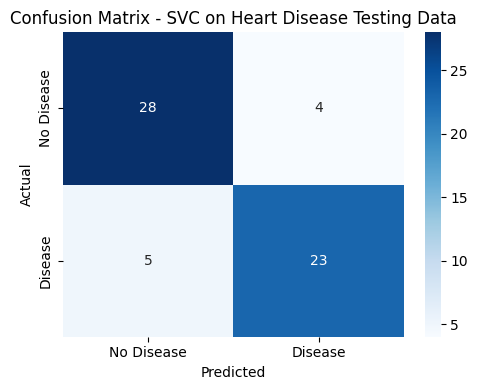

False negatives (sick patients predicted healthy): 5


In [22]:
"""
Purpose of this section:
-------------------------
Prints precision, recall and F1-score for each class, and draws the confusion matrix.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"],
    zero_division=0,
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"], labels=[0, 1])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"],
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

false_negatives = int(conf_matrix[1][0])
print("False negatives (sick patients predicted healthy):", false_negatives)

### Step 7.6: Cross-Validation (a more reliable accuracy estimate)

The test set is small, so one lucky or unlucky split can change the accuracy. **5-fold cross-validation** repeats the test five times: the data is cut into 5 parts, and each part takes a turn as the test set while the other four train the model. The average of the five scores is a steadier estimate.

In [23]:
"""
Purpose of this section:
-------------------------
Runs 5-fold stratified cross-validation with a fresh SVC on all the encoded data.
"""

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
all_input_vectors = sample_data_encoded.iloc[:, :-1]
all_output_labels = sample_data_encoded.iloc[:, -1]

cv_scores = cross_val_score(svm.SVC(gamma="auto", random_state=0), all_input_vectors, np.ravel(all_output_labels), cv=cv)

print("Accuracy of each fold:", np.round(cv_scores, 3))
print("Mean accuracy        :", round(cv_scores.mean(), 3))
print("Standard deviation   :", round(cv_scores.std(), 3))

Accuracy of each fold: [0.85  0.833 0.729 0.78  0.763]
Mean accuracy        : 0.791
Standard deviation   : 0.045


### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [24]:
"""
Purpose of this section:
-------------------------
Gets the patient details (ChestPain, ExerciseAngina, MajorVessels, Thalassemia).

- INTERACTIVE_MODE = False : a demo patient is used, so the notebook runs from
  top to bottom without typing anything.
- INTERACTIVE_MODE = True  : the notebook asks you to type the values. Wrong
  answers are rejected and asked again, so the notebook cannot crash here.
"""

INTERACTIVE_MODE = False

def ask_user(question, allowed_values):
    """Keep asking until the user types one of the allowed values (upper/lower case does not matter)."""
    while True:
        answer = input(question + " " + str(allowed_values) + ": ").strip()
        for value in allowed_values:
            if answer.lower() == value.lower():
                return value
        print("  Sorry, '" + answer + "' is not valid. Please type one of:", allowed_values)

if INTERACTIVE_MODE:
    chestpain_input = ask_user("Please enter the Chest Pain type", valid_values["ChestPain"])
    exerciseangina_input = ask_user("Does exercise cause chest pain?", valid_values["ExerciseAngina"])
    majorvessels_input = ask_user("Number of major vessels coloured by fluoroscopy", valid_values["MajorVessels"])
    thalassemia_input = ask_user("Please enter the Thalassemia result", valid_values["Thalassemia"])
else:
    chestpain_input = "Asymptomatic"
    exerciseangina_input = "Yes"
    majorvessels_input = "Two"
    thalassemia_input = "Reversible Defect"

print("ChestPain:", chestpain_input, "| ExerciseAngina:", exerciseangina_input,
      "| MajorVessels:", majorvessels_input, "| Thalassemia:", thalassemia_input)

ChestPain: Asymptomatic | ExerciseAngina: Yes | MajorVessels: Two | Thalassemia: Reversible Defect


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [25]:
"""
Purpose of this section:
-------------------------
Puts the user's input into a one-row table (feature vector) with the same
column names and order as the sample data.
"""

user_input = pd.DataFrame({
    "ChestPain": [chestpain_input],
    "ExerciseAngina": [exerciseangina_input],
    "MajorVessels": [majorvessels_input],
    "Thalassemia": [thalassemia_input],
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

      ChestPain ExerciseAngina MajorVessels        Thalassemia
0  Asymptomatic            Yes          Two  Reversible Defect


#### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [26]:
"""
Purpose of this section:
-------------------------
Encodes the user's input with the SAME trained label encoders used for the
training data. Using different encoders would give wrong numbers.
"""

unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exerciseangina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["MajorVessels"] = majorvessels_label_encoder.transform(user_input["MajorVessels"])
unseen_data_features["Thalassemia"] = thalassemia_label_encoder.transform(user_input["Thalassemia"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   ChestPain  ExerciseAngina  MajorVessels  Thalassemia
0          0               1             2            2


#### Step 8.4: Load the Saved Model

In [27]:
"""
Purpose of this section:
-------------------------
Loads the saved model from the .pkl file for the Application Phase.
"""

with open("svc_trained_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of the Unseen Instance and Return the Prediction to the User

In [28]:
"""
Purpose of this section:
-------------------------
Uses the trained model to predict heart disease for the patient entered above.
"""

predicted_heart_disease = int(model.predict(unseen_data_features)[0])

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE LIKELY"
else:
    prediction = "NO HEART DISEASE PREDICTED"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)
print("Educational demo only - this is NOT medical advice.")

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+
Educational demo only - this is NOT medical advice.


#### Step 8.5.2: Try More Patients

In [29]:
"""
Purpose of this section:
-------------------------
Wraps Steps 8.2 - 8.5 into one small function and tries several patients.
The same function is used again in Step 10.4 to check the web app.
"""

def predict_patient(chest_pain, exercise_angina, major_vessels, thalassemia):
    """Returns 1 (heart disease likely) or 0 (no heart disease predicted)."""
    patient = pd.DataFrame({
        "ChestPain": [chest_pain],
        "ExerciseAngina": [exercise_angina],
        "MajorVessels": [major_vessels],
        "Thalassemia": [thalassemia],
    })
    encoded_patient = pd.DataFrame({
        "ChestPain": chestpain_label_encoder.transform(patient["ChestPain"]),
        "ExerciseAngina": exerciseangina_label_encoder.transform(patient["ExerciseAngina"]),
        "MajorVessels": majorvessels_label_encoder.transform(patient["MajorVessels"]),
        "Thalassemia": thalassemia_label_encoder.transform(patient["Thalassemia"]),
    })
    return int(model.predict(encoded_patient)[0])

more_patients = [
    ("Asymptomatic", "Yes", "Three", "Reversible Defect"),
    ("Typical Angina", "No", "Zero", "Normal"),
    ("Non-anginal Pain", "No", "Zero", "Normal"),
    ("Atypical Angina", "Yes", "One", "Fixed Defect"),
]

patients_table = PrettyTable()
patients_table.field_names = ["ChestPain", "ExerciseAngina", "MajorVessels", "Thalassemia", "Prediction"]
for patient_values in more_patients:
    result = "HEART DISEASE LIKELY" if predict_patient(*patient_values) == 1 else "NO HEART DISEASE PREDICTED"
    patients_table.add_row(list(patient_values) + [result])
print(patients_table)

+------------------+----------------+--------------+-------------------+----------------------------+
|    ChestPain     | ExerciseAngina | MajorVessels |    Thalassemia    |         Prediction         |
+------------------+----------------+--------------+-------------------+----------------------------+
|   Asymptomatic   |      Yes       |    Three     | Reversible Defect |    HEART DISEASE LIKELY    |
|  Typical Angina  |       No       |     Zero     |       Normal      | NO HEART DISEASE PREDICTED |
| Non-anginal Pain |       No       |     Zero     |       Normal      | NO HEART DISEASE PREDICTED |
| Atypical Angina  |      Yes       |     One      |    Fixed Defect   |    HEART DISEASE LIKELY    |
+------------------+----------------+--------------+-------------------+----------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

After deployment, real users and domain experts (here: a cardiologist) test the model and tell us where it is wrong. Below is a **worked example for learning**. The "expected result" column is an *illustrative* expert expectation, not a real clinical review.

In [30]:
"""
Purpose of this section:
-------------------------
Step 9.1: Compares what an expert EXPECTS for some patients with what the
model really predicts, and flags every disagreement.
"""

feedback_cases = [
    # (reviewer, patient, expert expectation)
    ("Domain Expert (Cardiologist)", ("Asymptomatic", "Yes", "Three", "Reversible Defect"), 1),
    ("Domain Expert (Cardiologist)", ("Typical Angina", "No", "Zero", "Normal"), 0),
    ("Student Tester", ("Non-anginal Pain", "No", "Zero", "Normal"), 0),
    ("Student Tester", ("Atypical Angina", "Yes", "One", "Fixed Defect"), 1),
]

feedback_rows = []
for reviewer, patient_values, expected in feedback_cases:
    predicted = predict_patient(*patient_values)
    feedback_rows.append({
        "Reviewer": reviewer,
        "Patient": " / ".join(patient_values),
        "Expert expects": "Disease" if expected == 1 else "No disease",
        "Model predicts": "Disease" if predicted == 1 else "No disease",
        "Feedback": "Agrees with expert" if predicted == expected else "DISAGREES - investigate",
    })

example_feedback = pd.DataFrame(feedback_rows)
print(example_feedback.to_string(index=False))

                    Reviewer                                        Patient Expert expects Model predicts           Feedback
Domain Expert (Cardiologist) Asymptomatic / Yes / Three / Reversible Defect        Disease        Disease Agrees with expert
Domain Expert (Cardiologist)            Typical Angina / No / Zero / Normal     No disease     No disease Agrees with expert
              Student Tester          Non-anginal Pain / No / Zero / Normal     No disease     No disease Agrees with expert
              Student Tester     Atypical Angina / Yes / One / Fixed Defect        Disease        Disease Agrees with expert


#### Step 9.2: Make a List of Potential Improvements

In [31]:
"""
Purpose of this section:
-------------------------
Step 9.2: Improvements we could make after studying the feedback.
"""

improvements = [
    "Use more attributes (for example age, maximum heart rate, cholesterol) - the assignment limits us to 4, but a real system would use more",
    "Use the other three UCI hospitals (Hungarian, Swiss, VA Long Beach) to get more patients - they need extra care because of many missing values",
    "Use One-Hot Encoding instead of Label Encoding, because Label Encoding gives categories like chest-pain types a fake order (0 < 1 < 2 < 3)",
    "Tune the model (for example the C and gamma settings) with cross-validation, and compare more models such as Random Forest",
    "Give a probability or risk score, not only Yes/No, and always have a doctor review the result",
]
for number, item in enumerate(improvements, 1):
    print(str(number) + ".", item)

1. Use more attributes (for example age, maximum heart rate, cholesterol) - the assignment limits us to 4, but a real system would use more
2. Use the other three UCI hospitals (Hungarian, Swiss, VA Long Beach) to get more patients - they need extra care because of many missing values
3. Use One-Hot Encoding instead of Label Encoding, because Label Encoding gives categories like chest-pain types a fake order (0 < 1 < 2 < 3)
4. Tune the model (for example the C and gamma settings) with cross-validation, and compare more models such as Random Forest
5. Give a probability or risk score, not only Yes/No, and always have a doctor review the result


#### Step 9.3: Improve the Model Based on Feedback

Let us test one improvement from the list for real: **One-Hot Encoding instead of Label Encoding**. One-Hot Encoding turns every category into its own 0/1 column, so the model no longer sees a fake order. We compare both with the same 5-fold cross-validation.

In [32]:
"""
Purpose of this section:
-------------------------
Step 9.3: Compares Label Encoding with One-Hot Encoding using the same
5-fold cross-validation (Step 7.6). The deployed model is NOT changed here.
"""

text_inputs = sample_data[["ChestPain", "ExerciseAngina", "MajorVessels", "Thalassemia"]]
one_hot_inputs = OneHotEncoder(sparse_output=False).fit_transform(text_inputs)

cv_label = cross_val_score(svm.SVC(gamma="auto", random_state=0), all_input_vectors, np.ravel(all_output_labels), cv=cv)
cv_one_hot = cross_val_score(svm.SVC(gamma="auto", random_state=0), one_hot_inputs, np.ravel(all_output_labels), cv=cv)

print("Mean CV accuracy with Label Encoding  :", round(cv_label.mean(), 3))
print("Mean CV accuracy with One-Hot Encoding:", round(cv_one_hot.mean(), 3))
difference = cv_one_hot.mean() - cv_label.mean()
fold_spread = cv_label.std()
print("Difference (one-hot minus label)      :", round(difference, 3))
print("Fold-to-fold spread (std) of the scores:", round(fold_spread, 3))

if abs(difference) < fold_spread:
    print("\nResult: the difference is smaller than the normal fold-to-fold spread, so it is NOT conclusive.")
    print("One-Hot Encoding is worth trying in the next version, but we keep Label Encoding, as in the Titanic steps.")
elif difference > 0:
    print("\nResult: One-Hot Encoding is clearly better - use it in the next version of the system.")
else:
    print("\nResult: Label Encoding is clearly better here - keep it.")
print("The deployed model remains svc_trained_model.pkl from Step 6.4.")

Mean CV accuracy with Label Encoding  : 0.791
Mean CV accuracy with One-Hot Encoding: 0.808
Difference (one-hot minus label)      : 0.017
Fold-to-fold spread (std) of the scores: 0.045

Result: the difference is smaller than the normal fold-to-fold spread, so it is NOT conclusive.
One-Hot Encoding is worth trying in the next version, but we keep Label Encoding, as in the Titanic steps.
The deployed model remains svc_trained_model.pkl from Step 6.4.


## Step 10: Deploy Your Model on the Cloud

So far the model only works on your own computer while Jupyter is open. In this step we turn it into a **live website** that anyone can open in a browser.

#### Step 10.1: Why Deploy a Model?

A model is only useful if other people can use it. A small web app lets teachers, classmates and clients try the model without Python or Jupyter.

#### Step 10.2: Create the Deployment Folder

The next cell creates a folder called `heart-disease-app` and copies the three data files the web app needs into it: the trained model, the training data and the testing data.

In [33]:
"""
Purpose of this section:
-------------------------
Creates the deployment folder and copies the model and data files into it.
"""

APP_DIR = "heart-disease-app"
os.makedirs(APP_DIR, exist_ok=True)

for file_name in ["svc_trained_model.pkl", "training-data-encoded.csv", "testing-data-encoded.csv"]:
    shutil.copy(file_name, os.path.join(APP_DIR, file_name))

print("Folder:", APP_DIR)
print("Files :", sorted(os.listdir(APP_DIR)))

Folder: heart-disease-app
Files : ['README.md', 'app.py', 'flask_app.py', 'heart_model.py', 'requirements.txt', 'runtime.txt', 'svc_trained_model.pkl', 'testing-data-encoded.csv', 'training-data-encoded.csv']


#### Step 10.3: Write the Web App Code

The next six cells write the app files into `heart-disease-app` (each cell starts with `%%writefile`, which saves the cell text as a file). Read the code - it is short.

1. `heart_model.py` - the shared brain: encoders, model loading, prediction and the **automatic re-training fallback**
2. `app.py` - the Streamlit web app
3. `flask_app.py` - the same app in Flask (fallback for PythonAnywhere)
4. `requirements.txt` - packages the cloud must install
5. `runtime.txt` - Python version hint
6. `README.md` - deployment instructions

##### 1. `heart_model.py`

In [34]:
%%writefile heart-disease-app/heart_model.py
"""
heart_model.py - shared helper for the Heart Disease Prediction web apps
-------------------------------------------------------------------------
Both web apps (app.py for Streamlit and flask_app.py for PythonAnywhere)
use this one file, so the prediction logic is written only once.

What it does:
1. Keeps the list of the 4 input attributes and their allowed values.
2. Re-creates the same LabelEncoders that were trained in the notebook
   (LabelEncoder gives codes in alphabetical order, so fitting on the same
   fixed lists always gives the same numbers).
3. Loads the trained model from svc_trained_model.pkl.
4. FALLBACK: if the .pkl file is missing, damaged, or was saved with a
   different scikit-learn version, the model is re-trained automatically
   from training-data-encoded.csv (the same training data, same settings),
   so the app never crashes because of a model-file problem.
"""

from pathlib import Path
import pickle
import warnings

import numpy as np
import pandas as pd
from sklearn import svm
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

# All files live in the same folder as this script
BASE_DIR = Path(__file__).resolve().parent
MODEL_FILE = BASE_DIR / "svc_trained_model.pkl"
TRAIN_FILE = BASE_DIR / "training-data-encoded.csv"
TEST_FILE = BASE_DIR / "testing-data-encoded.csv"

# The 4 input attributes (exactly the same names and order as the notebook)
FEATURES = ["ChestPain", "ExerciseAngina", "MajorVessels", "Thalassemia"]
TARGET = "HeartDisease"

# Allowed values of every input attribute (same lists as notebook Step 5.1)
CATEGORIES = {
    "ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"],
    "ExerciseAngina": ["No", "Yes"],
    "MajorVessels": ["Zero", "One", "Two", "Three"],
    "Thalassemia": ["Normal", "Fixed Defect", "Reversible Defect"],
}
TARGET_CATEGORIES = ["Yes", "No"]

# What the numeric prediction means (the LabelEncoder gives No = 0, Yes = 1)
RESULT_TEXT = {1: "HEART DISEASE LIKELY", 0: "NO HEART DISEASE PREDICTED"}


def build_encoders():
    """Return one trained LabelEncoder per attribute (inputs and output)."""
    encoders = {name: LabelEncoder().fit(values) for name, values in CATEGORIES.items()}
    encoders[TARGET] = LabelEncoder().fit(TARGET_CATEGORIES)
    return encoders


def retrain_model():
    """Train the SVC again from the saved training data (fallback)."""
    training_data = pd.read_csv(TRAIN_FILE)
    input_vectors = training_data[FEATURES]
    output_labels = training_data[TARGET]
    model = svm.SVC(gamma="auto", random_state=0)
    model.fit(input_vectors, np.ravel(output_labels))
    return model


class ModelVersionMismatch(Exception):
    """The saved model was created with a different scikit-learn version."""


def load_model():
    """
    Load the saved model. Returns (model, status_text).
    If loading fails for ANY reason - or the file was saved with a different
    scikit-learn version, which can silently give wrong answers - fall back to
    re-training the same model from the saved training data.
    """
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            with open(MODEL_FILE, "rb") as file:
                model = pickle.load(file)
        if any(type(item.message).__name__ == "InconsistentVersionWarning" for item in caught):
            raise ModelVersionMismatch("model saved with another scikit-learn version")
        # Quick self-test: make sure the loaded model really works
        model.predict(pd.DataFrame([[0, 0, 0, 0]], columns=FEATURES))
        return model, "Model loaded from svc_trained_model.pkl"
    except Exception as error:
        model = retrain_model()
        return model, (
            "Saved model could not be used (" + type(error).__name__ + "), "
            "so it was re-trained from training-data-encoded.csv"
        )


def encode_inputs(values, encoders=None):
    """Turn {'ChestPain': 'Asymptomatic', ...} into a 1-row numeric DataFrame."""
    encoders = encoders or build_encoders()
    missing = [name for name in FEATURES if name not in values]
    if missing:
        raise ValueError("Missing input(s): " + ", ".join(missing))
    row = {}
    for name in FEATURES:
        value = values[name]
        if value not in CATEGORIES[name]:
            raise ValueError(
                "Invalid value " + repr(value) + " for " + name + ". Allowed values: " + ", ".join(CATEGORIES[name])
            )
        row[name] = [int(encoders[name].transform([value])[0])]
    return pd.DataFrame(row, columns=FEATURES)


def predict(model, values, encoders=None):
    """Return (prediction_code, encoded_feature_vector). 1 = heart disease, 0 = no."""
    encoded = encode_inputs(values, encoders)
    prediction = int(model.predict(encoded)[0])
    return prediction, encoded


def test_accuracy(model):
    """Accuracy of the model on testing-data-encoded.csv (None if unavailable)."""
    try:
        testing_data = pd.read_csv(TEST_FILE)
        predictions = model.predict(testing_data[FEATURES])
        return float(accuracy_score(testing_data[TARGET], predictions))
    except Exception:
        return None

Overwriting heart-disease-app/heart_model.py


##### 2. `app.py` (Streamlit)

In [35]:
%%writefile heart-disease-app/app.py
"""
Heart Disease Prediction System - Streamlit Web App
----------------------------------------------------
A small web page where anyone can pick 4 patient details and get a
prediction from the trained Support Vector Classifier (SVC).

Run locally:   streamlit run app.py
Deploy:        Streamlit Community Cloud (main file = app.py)

The model, encoders and fallback logic live in heart_model.py.
"""

import streamlit as st

import heart_model as hm

st.set_page_config(page_title="Heart Disease Predictor", page_icon="❤️", layout="centered")


@st.cache_resource
def load_everything():
    """Load the model once and keep it in memory (fast for every visitor)."""
    model, status = hm.load_model()
    return {
        "model": model,
        "status": status,
        "encoders": hm.build_encoders(),
        "accuracy": hm.test_accuracy(model),
    }


try:
    state = load_everything()
except Exception as load_error:
    st.title("❤️ Heart Disease Prediction System")
    st.error(
        "The model could not be loaded or re-trained: " + str(load_error)
        + ". Make sure svc_trained_model.pkl and training-data-encoded.csv "
        "are uploaded in the same folder as app.py."
    )
    st.stop()

st.title("❤️ Heart Disease Prediction System")
st.markdown(
    """
    This is a teaching demo built from the **Heart Disease Prediction System**
    notebook (UCI Heart Disease dataset, Cleveland data). Choose the four
    patient details below and the trained Support Vector Classifier (SVC)
    will predict whether heart disease is likely.
    """
)
if state["accuracy"] is not None:
    st.markdown(f"*Model accuracy on held-out test data: **{state['accuracy'] * 100:.0f}%***")

st.warning(
    "Educational demo only. This is NOT medical advice and must never be used "
    "to diagnose or treat a real patient."
)

st.divider()

col1, col2 = st.columns(2)
with col1:
    chest_pain = st.selectbox(
        "Chest Pain Type", hm.CATEGORIES["ChestPain"], index=3,
        help="Type of chest pain the patient reports.",
    )
    exercise_angina = st.selectbox(
        "Exercise-Induced Angina", hm.CATEGORIES["ExerciseAngina"],
        help="Does exercise cause chest pain (angina)?",
    )
with col2:
    major_vessels = st.selectbox(
        "Major Vessels Coloured by Fluoroscopy", hm.CATEGORIES["MajorVessels"],
        help="Number of major blood vessels (0 to 3) coloured by fluoroscopy.",
    )
    thalassemia = st.selectbox(
        "Thalassemia (Thallium Stress Test)", hm.CATEGORIES["Thalassemia"],
        help="Result of the thallium stress test.",
    )

if st.button("Predict Heart Disease", type="primary"):
    patient = {
        "ChestPain": chest_pain,
        "ExerciseAngina": exercise_angina,
        "MajorVessels": major_vessels,
        "Thalassemia": thalassemia,
    }
    try:
        prediction, encoded = hm.predict(state["model"], patient, state["encoders"])
        st.divider()
        if prediction == 1:
            st.error("### ⚠️ " + hm.RESULT_TEXT[1])
        else:
            st.success("### ✅ " + hm.RESULT_TEXT[0])
        with st.expander("See the encoded feature vector sent to the model"):
            st.dataframe(encoded, hide_index=True)
    except Exception as error:
        st.error("Sorry, the prediction could not be made: " + str(error))

if state["status"].startswith("Saved model could not be used"):
    st.info(state["status"])

st.divider()
st.caption(
    "Built for teaching purposes from the UCI Heart Disease dataset (Cleveland, "
    "297 complete patient records) using only 4 input attributes. Predictions "
    "reflect patterns in this small dataset, not a medical diagnosis."
)

Overwriting heart-disease-app/app.py


##### 3. `flask_app.py` (Flask / PythonAnywhere fallback)

In [36]:
%%writefile heart-disease-app/flask_app.py
"""
Heart Disease Prediction System - Flask Web App (PythonAnywhere version)
-------------------------------------------------------------------------
Same prediction logic as the Streamlit app, written as a plain Flask app so
it can run on PythonAnywhere (which hosts Flask / WSGI apps).

Run locally:   python flask_app.py    then open http://127.0.0.1:5000
PythonAnywhere: point the WSGI file to:  from flask_app import app as application
"""

from flask import Flask, render_template_string, request

import heart_model as hm

app = Flask(__name__)

# Load everything once when the app starts
try:
    MODEL, STATUS = hm.load_model()
    ENCODERS = hm.build_encoders()
    ACCURACY = hm.test_accuracy(MODEL)
    LOAD_ERROR = None
except Exception as load_problem:
    MODEL, STATUS, ENCODERS, ACCURACY = None, None, None, None
    LOAD_ERROR = (
        "The model could not be loaded or re-trained: " + str(load_problem)
        + ". Make sure svc_trained_model.pkl and training-data-encoded.csv "
        "are in the same folder as flask_app.py."
    )

PAGE = """
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Heart Disease Predictor</title>
  <style>
    body { font-family: Arial, sans-serif; background: #f4f6f8; margin: 0; padding: 20px; }
    .card { max-width: 560px; margin: 0 auto; background: #fff; padding: 24px;
            border-radius: 10px; box-shadow: 0 2px 8px rgba(0,0,0,.12); }
    h1 { margin-top: 0; font-size: 1.6em; }
    label { display: block; margin-top: 14px; font-weight: bold; }
    select, button { width: 100%; padding: 10px; margin-top: 6px; font-size: 1em; }
    button { background: #c0392b; color: #fff; border: 0; border-radius: 6px; cursor: pointer; }
    .result { margin-top: 20px; padding: 14px; border-radius: 6px; font-weight: bold; text-align: center; }
    .bad { background: #fdecea; color: #b71c1c; }
    .good { background: #e8f5e9; color: #1b5e20; }
    .warn { background: #fff8e1; color: #6d4c00; padding: 10px; border-radius: 6px; margin: 14px 0; font-size: .9em; }
    .small { color: #666; font-size: .85em; margin-top: 18px; }
  </style>
</head>
<body>
  <div class="card">
    <h1>&#10084;&#65039; Heart Disease Prediction System</h1>
    <p>Choose the four patient details and the trained Support Vector Classifier
       (SVC) will predict whether heart disease is likely.</p>
    {% if accuracy is not none %}
      <p><em>Model accuracy on held-out test data: <b>{{ "%.0f"|format(accuracy * 100) }}%</b></em></p>
    {% endif %}
    <div class="warn">Educational demo only. This is NOT medical advice.</div>

    <form method="post">
      {% for name, label in fields %}
        <label for="{{ name }}">{{ label }}</label>
        <select name="{{ name }}" id="{{ name }}">
          {% for option in categories[name] %}
            <option value="{{ option }}" {% if chosen[name] == option %}selected{% endif %}>{{ option }}</option>
          {% endfor %}
        </select>
      {% endfor %}
      <button type="submit">Predict Heart Disease</button>
    </form>

    {% if error %}
      <div class="result bad">{{ error }}</div>
    {% elif result is not none %}
      <div class="result {{ 'bad' if prediction == 1 else 'good' }}">{{ result }}</div>
    {% endif %}

    <p class="small">Built for teaching purposes from the UCI Heart Disease dataset
       (Cleveland) using only 4 input attributes.</p>
  </div>
</body>
</html>
"""

FIELDS = [
    ("ChestPain", "Chest Pain Type"),
    ("ExerciseAngina", "Exercise-Induced Angina"),
    ("MajorVessels", "Major Vessels Coloured by Fluoroscopy (0-3)"),
    ("Thalassemia", "Thalassemia (Thallium Stress Test)"),
]


@app.route("/", methods=["GET", "POST"])
def home():
    chosen = {name: hm.CATEGORIES[name][0] for name, _ in FIELDS}
    result, prediction, error = None, None, None

    if LOAD_ERROR:
        error = LOAD_ERROR
    elif request.method == "POST":
        for name, _ in FIELDS:
            chosen[name] = request.form.get(name, chosen[name])
        try:
            prediction, _ = hm.predict(MODEL, chosen, ENCODERS)
            result = hm.RESULT_TEXT[prediction]
        except Exception as problem:
            error = "Sorry, the prediction could not be made: " + str(problem)

    return render_template_string(
        PAGE,
        fields=FIELDS,
        categories=hm.CATEGORIES,
        chosen=chosen,
        result=result,
        prediction=prediction,
        error=error,
        accuracy=ACCURACY,
    )


if __name__ == "__main__":
    app.run(debug=True)

Overwriting heart-disease-app/flask_app.py


##### 4. `requirements.txt`

In [37]:
%%writefile heart-disease-app/requirements.txt
streamlit>=1.30
scikit-learn>=1.2
pandas>=1.5
numpy>=1.23

Overwriting heart-disease-app/requirements.txt


##### 5. `runtime.txt`

In [38]:
%%writefile heart-disease-app/runtime.txt
3.11

Overwriting heart-disease-app/runtime.txt


##### 6. `README.md`

In [39]:
%%writefile heart-disease-app/README.md
# Heart Disease Prediction System - Web App

A small web app that predicts whether heart disease is likely from **4 input attributes**
(Chest Pain Type, Exercise-Induced Angina, Major Vessels, Thalassemia), using a Support
Vector Classifier trained on the UCI Heart Disease dataset (Cleveland data).

> Educational demo only. Not medical advice.

## Files in this folder

| File | Purpose |
|---|---|
| `app.py` | Streamlit web app (main file for Streamlit Community Cloud) |
| `flask_app.py` | Same app written in Flask (for PythonAnywhere) |
| `heart_model.py` | Shared code: encoders, model loading, prediction, **automatic re-training fallback** |
| `svc_trained_model.pkl` | Trained model saved by the notebook |
| `training-data-encoded.csv` | Training data (used only if the model has to be re-trained) |
| `testing-data-encoded.csv` | Test data (used to show the accuracy on the page) |
| `requirements.txt` | Python packages for deployment |

## Run on your own computer first

```
pip install -r requirements.txt
streamlit run app.py
```
It opens at http://localhost:8501

## Option A (recommended): Streamlit Community Cloud (free)

1. Create a **public** GitHub repository and upload everything in this folder (files at the top level, not inside a sub-folder).
2. Go to https://share.streamlit.io and sign in with GitHub.
3. Click **Create app** -> **Deploy a public app from GitHub**.
4. Repository = your repo, Branch = `main`, Main file path = `app.py`.
5. Click **Deploy** and wait a few minutes. Copy your `https://<name>.streamlit.app` link.
6. If the build fails, open **Manage app -> Settings -> Python version** and pick **3.11** or **3.12**, then reboot.

## Option B (fallback): PythonAnywhere (Flask)

1. Sign up at https://www.pythonanywhere.com (free account) and open the **Files** tab.
2. Create a folder `heart-disease-app` and upload every file from this folder into it.
3. Open the **Web** tab -> **Add a new web app** -> **Flask** (pick a Python version).
4. Open the WSGI configuration file and replace its content with:
   ```python
   import sys
   path = "/home/YOUR_USERNAME/heart-disease-app"
   if path not in sys.path:
       sys.path.insert(0, path)
   from flask_app import app as application
   ```
5. In a **Bash console** check the packages: `python -c "import sklearn, pandas"` (if missing: `pip install --user scikit-learn pandas`).
6. Press **Reload** on the Web tab. Your link is `https://YOUR_USERNAME.pythonanywhere.com`.

(Follow your instructor's PythonAnywhere tutorial for the exact clicks if the screens look different.)

## Option C (fallback): Hugging Face Spaces

Create a new Space, choose the **Streamlit** SDK, upload the same files, and keep `app.py` as the app file.

## If the model file ever fails to load

`heart_model.py` catches the error and re-trains the same SVC from `training-data-encoded.csv`
automatically, so the app keeps working (for example after a scikit-learn version change).

Overwriting heart-disease-app/README.md


#### Step 10.4: Test the Deployment Folder Locally

Before uploading anything, we test the files we just wrote. The next cell:

1. Loads the **web app's** model through `heart_model.py`.
2. Tries **all 96 possible patients** (4 x 2 x 4 x 3 combinations) and checks that the web app gives the **same answer as this notebook**.
3. Tests the **fallback**: it re-trains the model from `training-data-encoded.csv` and checks that it also gives the same answers.

In [40]:
"""
Purpose of this section:
-------------------------
Checks that the web app code and this notebook agree for EVERY possible patient,
and that the automatic re-training fallback gives the same answers.
"""

import importlib
import itertools

if APP_DIR not in sys.path:
    sys.path.insert(0, APP_DIR)
import heart_model
heart_model = importlib.reload(heart_model)

app_model, app_status = heart_model.load_model()
fallback_model = heart_model.retrain_model()
print("Web app model status:", app_status)

attribute_names = ["ChestPain", "ExerciseAngina", "MajorVessels", "Thalassemia"]
all_patients = list(itertools.product(*[valid_values[name] for name in attribute_names]))

app_mismatches = 0
fallback_mismatches = 0
for patient_values in all_patients:
    notebook_answer = predict_patient(*patient_values)
    patient_dict = dict(zip(attribute_names, patient_values))
    app_answer, _ = heart_model.predict(app_model, patient_dict)
    fallback_answer, _ = heart_model.predict(fallback_model, patient_dict)
    app_mismatches += int(app_answer != notebook_answer)
    fallback_mismatches += int(fallback_answer != notebook_answer)

print("\nPatients tested                                   :", len(all_patients))
print("Web app answers different from the notebook       :", app_mismatches)
print("Fallback (re-trained) answers different from notebook:", fallback_mismatches)
print("Accuracy shown by the web app                     :", round(heart_model.test_accuracy(app_model), 2))
print("Accuracy in this notebook (Step 7.4)              :", round(model_accuracy_score, 2))

if app_mismatches == 0 and fallback_mismatches == 0:
    print("\nAll checks passed: the deployment folder is ready to upload.")
else:
    print("\nWARNING: some answers differ - re-run the notebook from the top (Restart & Run All).")

Web app model status: Model loaded from svc_trained_model.pkl

Patients tested                                   : 96
Web app answers different from the notebook       : 0
Fallback (re-trained) answers different from notebook: 0
Accuracy shown by the web app                     : 0.85
Accuracy in this notebook (Step 7.4)              : 0.85

All checks passed: the deployment folder is ready to upload.


#### Step 10.5: Upload to GitHub and Deploy on Streamlit Community Cloud

**Optional - try the app on your computer first** (open a terminal in the `heart-disease-app` folder):
```
pip install -r requirements.txt
streamlit run app.py
```

**A. Put the folder on GitHub**
1. Sign up for a free account at https://github.com.
2. Click **+** -> **New repository**. Name it (for example `heart-disease-predictor`), keep it **Public**, click **Create repository**.
3. Click **Add file -> Upload files** and drag in **the files from inside `heart-disease-app`** (so `app.py` is at the top level of the repository, not inside a sub-folder). Click **Commit changes**.

**B. Deploy**
1. Go to https://share.streamlit.io and click **Sign in with GitHub** (free for public apps).
2. Click **Create app -> Deploy a public app from GitHub**.
3. Fill in: **Repository** = `<your-username>/heart-disease-predictor`, **Branch** = `main`, **Main file path** = `app.py`.
4. Click **Deploy**. The first build takes a few minutes.
5. Copy the public link `https://<something>.streamlit.app`.

**C. Test the live app** - choose *Asymptomatic / Yes / Two / Reversible Defect* and click **Predict**. The answer must be the same as in Step 8.5.1 of this notebook.

#### Step 10.6: Fallback Options (If Streamlit Cloud Does Not Work)

The assignment accepts any cloud deployment, so you have two backups. Both use the same `heart-disease-app` files.

**Fallback 1 - PythonAnywhere (uses `flask_app.py`)**
1. Sign up at https://www.pythonanywhere.com (free account) and open the **Files** tab. Create the folder `heart-disease-app` and upload all files into it.
2. Open the **Web** tab -> **Add a new web app** -> **Flask**.
3. Open the WSGI configuration file and replace its content with:
```python
import sys
path = "/home/YOUR_USERNAME/heart-disease-app"
if path not in sys.path:
    sys.path.insert(0, path)
from flask_app import app as application
```
4. In a **Bash console**, check the packages with `python -c "import sklearn, pandas"` (if one is missing: `pip install --user scikit-learn pandas`).
5. Press **Reload**. Your link is `https://YOUR_USERNAME.pythonanywhere.com`.

*(If the PythonAnywhere screens look different, follow the PythonAnywhere tutorial given by your instructor.)*

**Fallback 2 - Hugging Face Spaces**
Create a new Space, choose the **Streamlit** SDK, upload the same files and keep `app.py` as the app file.

**Built-in fallback inside the code:** if the saved model file cannot be loaded (for example, after a scikit-learn version change on the cloud), `heart_model.py` automatically re-trains the same model from `training-data-encoded.csv`. The app keeps working and Step 10.4 proves the answers are identical.

#### Step 10.7: Troubleshooting

- **`ModuleNotFoundError` for a package that is in `requirements.txt`:** the cloud may default to a very new Python version without ready-made packages. Open **Manage app -> Settings -> Python version**, choose **3.11** or **3.12**, save (the app reboots).
- **"Your app is in the oven" for a very long time:** the build is probably stuck in a crash loop. Click **Manage app**, read the red lines in the log, fix `requirements.txt` or the Python version, then **Reboot**.
- **`requirements.txt` seems ignored:** it must be in the **same folder as `app.py`** (the top level of the repository).
- **"File not found: svc_trained_model.pkl":** the `.pkl` and the two `.csv` files must be uploaded next to `app.py`.
- **Notebook error "processed.cleveland.data not found":** put the UCI file in the same folder as the notebook (or connect to the internet so Step 2 can download it).

#### Step 10.8: Put Your Live Link at the Top of This Notebook

Scroll to the first cell of this notebook, replace `https://YOUR-APP-NAME.streamlit.app` with your real link, and save. The assignment requires the live link at the very top of the notebook.

In [41]:
"""
Conclusion - the numbers below are filled in automatically from this run.
"""

best_row = comparison_df.sort_values("Accuracy", ascending=False).iloc[0]

display(Markdown(f"""
## Conclusion

We built and deployed a complete machine learning system on structured data - Data Collection, Data Understanding, Pre-processing, Label Encoding, then the four phases of the ML cycle (Training, Testing, Application, Feedback) - to predict heart disease from **only four attributes**: Chest Pain Type, Exercise-Induced Angina, Major Vessels and Thalassemia. The four were chosen with Chi-square and Mutual Information scores, not by guessing.

- **Data:** {len(sample_data)} patients (6 of the original 303 were removed because of missing values).
- **Accuracy on the held-out test set:** {model_accuracy_score:.2f} ({len(model_predictions)} patients), with {false_negatives} false negative(s).
- **5-fold cross-validation:** {cv_scores.mean():.2f} on average (+/- {cv_scores.std():.2f}). This is the more reliable number, because the test set is small.
- **Model comparison:** SVC, Logistic Regression and Decision Tree all reached similar accuracy ({comparison_df["Accuracy"].min():.2f} to {comparison_df["Accuracy"].max():.2f}); the best single test score was {best_row["Model"]} ({best_row["Accuracy"]:.2f}).
- **Deployment:** the SVC is served by a Streamlit web app (with a Flask / PythonAnywhere version and an automatic re-training fallback), and Step 10.4 confirmed that the web app and the notebook agree on all {len(all_patients)} possible patients.

**Limits:** only 4 attributes, a small dataset from one hospital, and Label Encoding that adds a fake order to categories. This is a classroom demo, **not a medical device**.
"""))


## Conclusion

We built and deployed a complete machine learning system on structured data - Data Collection, Data Understanding, Pre-processing, Label Encoding, then the four phases of the ML cycle (Training, Testing, Application, Feedback) - to predict heart disease from **only four attributes**: Chest Pain Type, Exercise-Induced Angina, Major Vessels and Thalassemia. The four were chosen with Chi-square and Mutual Information scores, not by guessing.

- **Data:** 297 patients (6 of the original 303 were removed because of missing values).
- **Accuracy on the held-out test set:** 0.85 (60 patients), with 5 false negative(s).
- **5-fold cross-validation:** 0.79 on average (+/- 0.04). This is the more reliable number, because the test set is small.
- **Model comparison:** SVC, Logistic Regression and Decision Tree all reached similar accuracy (0.80 to 0.85); the best single test score was SVC (gamma=auto) (0.85).
- **Deployment:** the SVC is served by a Streamlit web app (with a Flask / PythonAnywhere version and an automatic re-training fallback), and Step 10.4 confirmed that the web app and the notebook agree on all 96 possible patients.

**Limits:** only 4 attributes, a small dataset from one hospital, and Label Encoding that adds a fake order to categories. This is a classroom demo, **not a medical device**.
